<a href="https://colab.research.google.com/github/cursuri-inf/IPAP/blob/main/saptamana-01/curs015_demonstratii.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Cursul 1.5. Demonstrațiile

Caietul conține demonstrațiile de la cursul 1.5, „De la perceptron la rețeaua neuronală”, cu rezultatele salvate. Titlurile de mai jos au numerele capitolelor din suport. Exemplul este un magazin online; comenzile din secțiunile D4 și D5 sunt simulate.

**Cum lucrați:**

1. Deschideți caietul cu butonul „Open in Colab” de mai sus. Colab avertizează că documentul nu a fost creat de Google: caietul vine din depozitul cursului, așa că alegeți „Run anyway”.
2. Înainte să schimbați ceva: File → Save a copy in Drive; lucrați în copie.
3. Rezultatele salvate se văd și fără rulare. Ca să le obțineți din nou, rulați celulele în ordine, de sus în jos, cu Shift+Enter.
4. Nu trebuie să înțelegeți fiecare rând de cod: citiți textul, rulați celula și comparați rezultatul cu cel din suport. Celulele „Încercați acum” vă cer să schimbați un singur număr.
5. Notițele dumneavoastră: după fiecare demonstrație aveți o celulă „Notițele mele” (dublu clic pentru editare). Puteți lăsa și comentarii pe marginea din dreapta a oricărei celule: clic dreapta pe celulă, apoi „Add a comment” (sau Ctrl+Alt+M).

Caietul rulează pe procesor, în câteva minute; un GPU nu este necesar. Nu se predă și nu se notează.

## 0. Pornire

Bibliotecile și versiunile lor.

In [1]:
import sys
import math
import torch
from torch import nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

print("Python ", sys.version.split()[0])
print("PyTorch", torch.__version__)

Python  3.13.16
PyTorch 2.14.1+cpu


## D1. Perceptronul (§2–§3)

### Livrăm gratuit? (§2.2–§2.3)

Intrările: valoarea comenzii, în sute de lei, și cardul de fidelitate (1 dacă clientul îl are, 0 dacă nu). Ponderile spun cât contează fiecare intrare: 1 pentru valoare, 2 pentru card. Termenul liber, −3, este pragul mutat de cealaltă parte: livrăm gratuit dacă suma ponderată plus termenul liber nu este negativă.

In [2]:
def perceptron(x, w, b):
    s = sum(xi * wi for xi, wi in zip(x, w)) + b
    return s, (1 if s >= 0 else 0)

w = [1, 2]   # ponderile: valoarea, cardul
comenzi = {"A": [2.5, 0], "B": [1.5, 1],
           "C": [0.8, 1]}
for b in (-3, -2):   # magazin strict, generos
    for nume, x in comenzi.items():
        s, r = perceptron(x, w, b)
        print(f"b={b} {nume}: {s:+.1f} -> "
              + ("da" if r else "nu"))

b=-3 A: -0.5 -> nu
b=-3 B: +0.5 -> da
b=-3 C: -0.2 -> nu
b=-2 A: +0.5 -> da
b=-2 B: +1.5 -> da
b=-2 C: +0.8 -> da


**Încercați acum.** Adăugați în `comenzi` o comandă de 300 de lei fără card (`[3, 0]`) și una de 200 de lei fără card (`[2, 0]`). Ce răspunde magazinul strict? Dar cel generos?

### Regula lui Rosenblatt (§3.1)

Perceptronul pornește de la ponderi 0 și termen liber 0 și ia pe rând cele patru exemple. Dacă răspunsul e corect, nu se schimbă nimic. Dacă a greșit, fiecare pondere se schimbă cu (y − ŷ) · x, iar termenul liber cu (y − ŷ), unde y este răspunsul corect și ŷ răspunsul dat. Aici „da” înseamnă o sumă strict pozitivă.

Exemplul: „Livrăm gratuit dacă comanda trece de 200 de lei sau clientul are card” (SAU). Intrările sunt 0 sau 1.

In [3]:
X4 = [(0, 0), (1, 0), (0, 1), (1, 1)]

def o_trecere(w, b, y):
    greseli = 0
    for x, yc in zip(X4, y):
        s = w[0] * x[0] + w[1] * x[1] + b
        r = 1 if s > 0 else 0
        if r != yc:
            greseli += 1
            w = [w[0] + (yc - r) * x[0],
                 w[1] + (yc - r) * x[1]]
            b = b + (yc - r)
    return w, b, greseli

def invata(y, treceri=10):
    w, b = [0, 0], 0
    for t in range(1, treceri + 1):
        w, b, g = o_trecere(w, b, y)
        gr = "greșeală" if g == 1 else "greșeli"
        print(f"trecerea {t}: {g} {gr},",
              f"w={w}, b={b}")
        if g == 0:
            return w, b
    return None

SAU = [0, 1, 1, 1]
invata(SAU)

trecerea 1: 1 greșeală, w=[1, 0], b=1
trecerea 2: 2 greșeli, w=[1, 1], b=1
trecerea 3: 1 greșeală, w=[1, 1], b=0
trecerea 4: 0 greșeli, w=[1, 1], b=0


([1, 1], 0)

Același perceptron, pentru „cadou dacă comanda trece de 200 de lei **și** clientul are card” (ȘI):

In [4]:
SI = [0, 0, 0, 1]
invata(SI)

trecerea 1: 1 greșeală, w=[1, 1], b=1
trecerea 2: 3 greșeli, w=[1, 2], b=0
trecerea 3: 3 greșeli, w=[1, 2], b=-1
trecerea 4: 2 greșeli, w=[2, 2], b=-1
trecerea 5: 1 greșeală, w=[1, 2], b=-2
trecerea 6: 0 greșeli, w=[1, 2], b=-2


([1, 2], -2)

### Comanda suspectă (§3.2)

„Semnalăm comanda dacă țara cardului diferă de țara de livrare”: prima intrare spune dacă cardul e străin, a doua dacă livrarea e în străinătate. Este funcția XOR. Perceptronul nu se oprește: repetă la nesfârșit aceleași corecții.

In [5]:
XOR = [0, 1, 1, 0]
rezultat = invata(XOR, treceri=6)
print("a învățat" if rezultat else
      "nu învață: nicio dreaptă nu separă cazurile")

trecerea 1: 2 greșeli, w=[0, -1], b=0
trecerea 2: 3 greșeli, w=[0, -1], b=1
trecerea 3: 4 greșeli, w=[0, -1], b=1
trecerea 4: 4 greșeli, w=[0, -1], b=1
trecerea 5: 4 greșeli, w=[0, -1], b=1
trecerea 6: 4 greșeli, w=[0, -1], b=1
nu învață: nicio dreaptă nu separă cazurile


### Notițele mele

…

## D2. Rețeaua rezolvă comanda suspectă (§4.3)

Doi neuroni ascunși cu ReLU, calculați de mână: h₁ = ReLU(x₁ + x₂) spune „măcar o condiție”, h₂ = ReLU(x₁ + x₂ − 1) spune „amândouă”, iar ieșirea este h₁ − 2 · h₂.

In [6]:
def relu(z):
    return max(0, z)

for x1, x2 in X4:
    h1 = relu(x1 + x2)
    h2 = relu(x1 + x2 - 1)
    print(x1, x2, "->", h1, h2, "->", h1 - 2 * h2)

0 0 -> 0 0 -> 0
1 0 -> 1 0 -> 1
0 1 -> 1 0 -> 1
1 1 -> 2 1 -> 0


Aceeași rețea, de data aceasta învățată singură: 2 neuroni ascunși, pornită de 20 de ori, de la 20 de valori aleatoare diferite (semințele 0–19). De câte ori ajunge la răspunsurile corecte pentru toate cele patru comenzi, cu fiecare funcție de activare?

In [7]:
X = torch.tensor(X4, dtype=torch.float32)
y = torch.tensor([[0.], [1.], [1.], [0.]])

def reuseste(activare, samanta, ascunsi=2):
    torch.manual_seed(samanta)
    m = nn.Sequential(nn.Linear(2, ascunsi),
                      activare(),
                      nn.Linear(ascunsi, 1))
    o = torch.optim.Adam(m.parameters(), lr=0.05)
    for _ in range(2000):
        o.zero_grad()
        F.binary_cross_entropy_with_logits(
            m(X), y).backward()
        o.step()
    with torch.no_grad():
        return bool(((m(X) > 0).float() == y).all())

for nume, act in [("ReLU", nn.ReLU),
                  ("Leaky ReLU", nn.LeakyReLU),
                  ("tanh", nn.Tanh),
                  ("sigmoida", nn.Sigmoid)]:
    n = sum(reuseste(act, s) for s in range(20))
    print(f"{nume}: {n} din 20")
n4 = sum(reuseste(nn.ReLU, s, 4) for s in range(20))
print(f"ReLU, 4 neuroni ascunși: {n4} din 20")

ReLU: 6 din 20


Leaky ReLU: 13 din 20


tanh: 9 din 20


sigmoida: 8 din 20


ReLU, 4 neuroni ascunși: 12 din 20


### Notițele mele

…

## D3. Funcțiile de activare și pantele lor (§6–§7)

Valoarea fiecărei funcții și panta ei în câteva puncte. Panta o calculează PyTorch (`backward`), la fel ca în antrenare.

In [8]:
functii = {
    "treapta": lambda z: (z >= 0).float(),
    "sigmoida": torch.sigmoid,
    "tanh": torch.tanh,
    "ReLU": torch.relu,
    "Leaky ReLU": lambda z: F.leaky_relu(z, 0.01),
    "ELU": F.elu,
    "GELU": F.gelu,
}
puncte = [-5.0, -2.0, 0.0, 3.0, 5.0]
print("x:", puncte)
for nume, f in functii.items():
    z = torch.tensor(puncte, requires_grad=True)
    v = f(z)
    if v.requires_grad:
        v.sum().backward()
        p = z.grad.tolist()
    else:
        p = [0.0] * len(puncte)
    vr = [round(a, 4) for a in v.tolist()]
    pr = [round(a, 4) for a in p]
    print(nume)
    print("  valoarea:", vr)
    print("  panta:   ", pr)

x: [-5.0, -2.0, 0.0, 3.0, 5.0]
treapta
  valoarea: [0.0, 0.0, 1.0, 1.0, 1.0]
  panta:    [0.0, 0.0, 0.0, 0.0, 0.0]
sigmoida
  valoarea: [0.0067, 0.1192, 0.5, 0.9526, 0.9933]
  panta:    [0.0066, 0.105, 0.25, 0.0452, 0.0066]
tanh
  valoarea: [-0.9999, -0.964, 0.0, 0.9951, 0.9999]
  panta:    [0.0002, 0.0707, 1.0, 0.0099, 0.0002]
ReLU
  valoarea: [0.0, 0.0, 0.0, 3.0, 5.0]
  panta:    [0.0, 0.0, 0.0, 1.0, 1.0]
Leaky ReLU
  valoarea: [-0.05, -0.02, 0.0, 3.0, 5.0]
  panta:    [0.01, 0.01, 0.01, 1.0, 1.0]
ELU
  valoarea: [-0.9933, -0.8647, 0.0, 3.0, 5.0]
  panta:    [0.0067, 0.1353, 1.0, 1.0, 1.0]
GELU
  valoarea: [-0.0, -0.0455, 0.0, 2.9959, 5.0]
  panta:    [-0.0, -0.0852, 0.5, 1.0119, 1.0]


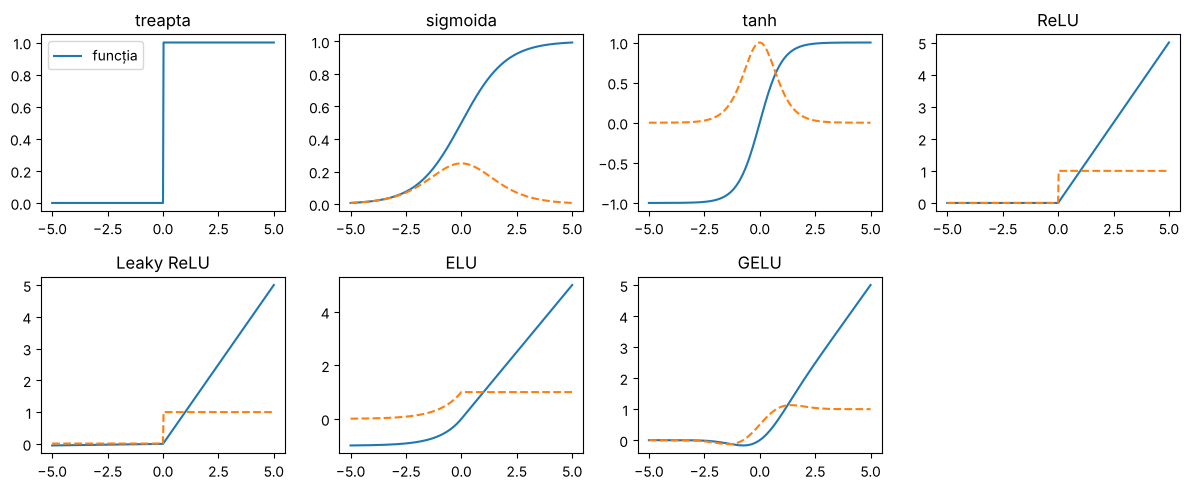

In [9]:
z = torch.linspace(-5, 5, 401, requires_grad=True)
fig, axe = plt.subplots(2, 4, figsize=(12, 5))
for ax, (nume, f) in zip(axe.flat, functii.items()):
    v = f(z)
    ax.plot(z.detach(), v.detach(), label="funcția")
    if v.requires_grad:
        g, = torch.autograd.grad(v.sum(), z)
        ax.plot(z.detach(), g, "--", label="panta")
    ax.set_title(nume)
axe.flat[-1].axis("off")
axe.flat[0].legend()
plt.tight_layout()
plt.show()

**Saturarea.** O corecție care trece prin zece straturi cu sigmoidă se înmulțește de zece ori cu panta sigmoidei, cel mult 0,25:

In [10]:
print("0,25 la puterea 10:", 0.25 ** 10)
panta3 = 1 - math.tanh(3) ** 2
print("panta tanh la 3:", round(panta3, 4))

0,25 la puterea 10: 9.5367431640625e-07
panta tanh la 3: 0.0099


### Notițele mele

…

## D4. Comenzile simulate (§3.2, §4.3, §6, §7)

400 de comenzi pentru antrenare și 200 pentru validare, **simulate**. Fiecare comandă are două scoruri între 0 și 1: cât de probabil e cardul străin și cât de probabilă e livrarea în străinătate. Comanda e suspectă dacă exact unul trece de 0,5; la 5% dintre comenzi eticheta e întoarsă, ca zgomotul din datele reale.

In [11]:
def comenzi(n, samanta):
    g = torch.Generator().manual_seed(samanta)
    x = torch.rand(n, 2, generator=g)
    y = (x[:, 0] > 0.5) ^ (x[:, 1] > 0.5)
    y = y.float()
    zgomot = torch.rand(n, generator=g) < 0.05
    y[zgomot] = 1 - y[zgomot]
    # intrările centrate în 0, între -1 și 1
    return (x - 0.5) * 2, y.unsqueeze(1)

xa, ya = comenzi(400, 1)   # antrenare
xv, yv = comenzi(200, 2)   # validare
print("suspecte:", int(ya.sum()), "din 400;",
      int(yv.sum()), "din 200")
# ghicitul: mereu răspunsul cel mai frecvent
fr = float(ya.mean() > 0.5)
print("ghicitul, pe validare:",
      f"{float((yv == fr).float().mean()):.1%}")

suspecte: 192 din 400; 104 din 200
ghicitul, pe validare: 48.0%


In [12]:
def retea(ascunsi=16, activare=nn.ReLU, ini=None):
    torch.manual_seed(0)
    m = nn.Sequential(nn.Linear(2, ascunsi),
                      activare(),
                      nn.Linear(ascunsi, 1))
    if ini:
        for strat in (m[0], m[2]):
            ini(strat)
    return m

def antreneaza(m, rata=0.1, epoci=300, opt="sgd"):
    torch.manual_seed(0)
    O = (torch.optim.SGD if opt == "sgd"
         else torch.optim.Adam)
    o = O(m.parameters(), lr=rata)
    for _ in range(epoci):
        ordine = torch.randperm(400)
        for i in range(0, 400, 32):
            k = ordine[i:i + 32]
            o.zero_grad()
            F.binary_cross_entropy_with_logits(
                m(xa[k]), ya[k]).backward()
            o.step()

def acuratete(m, x, y):
    with torch.no_grad():
        return float(((m(x) > 0).float() == y)
                     .float().mean())

def inactivi(m):   # neuronii ReLU mereu 0
    with torch.no_grad():
        h = torch.relu(m[0](xa))
    return int((h.max(0).values <= 0).sum())

Un singur neuron (o dreaptă) față de o rețea cu 16 neuroni ascunși:

In [13]:
torch.manual_seed(0)
neuron = nn.Sequential(nn.Linear(2, 1))
antreneaza(neuron)
m = retea()
antreneaza(m)
for nume, model in (("un neuron", neuron),
                    ("rețeaua 2-16-1", m)):
    a = acuratete(model, xa, ya)
    v = acuratete(model, xv, yv)
    print(f"{nume}: antrenare {a:.1%},",
          f"validare {v:.1%}")

un neuron: antrenare 61.5%, validare 57.5%
rețeaua 2-16-1: antrenare 93.5%, validare 90.0%


Aceeași rețea, cu fiecare funcție de activare, antrenată la fel (300 de treceri prin date, pasul 0,1):

In [14]:
for nume, act in [("sigmoida", nn.Sigmoid),
                  ("tanh", nn.Tanh),
                  ("ReLU", nn.ReLU),
                  ("Leaky ReLU", nn.LeakyReLU),
                  ("ELU", nn.ELU),
                  ("GELU", nn.GELU)]:
    m = retea(activare=act)
    antreneaza(m)
    print(f"{nume}: validare "
          f"{acuratete(m, xv, yv):.1%}")

sigmoida: validare 86.0%


tanh: validare 89.5%


ReLU: validare 90.0%


Leaky ReLU: validare 90.0%


ELU: validare 90.5%


GELU: validare 90.0%


**Neuronii inactivi.** Cu pași din ce în ce mai mari (optimizatorul Adam), câți dintre cei 16 neuroni ReLU ajung să dea 0 pentru toate comenzile?

In [15]:
for rata in (0.01, 0.1, 0.5, 1.0):
    m = retea()
    antreneaza(m, rata=rata, opt="adam")
    print(f"rata {rata}: {inactivi(m)} inactivi"
          f" din 16, validare "
          f"{acuratete(m, xv, yv):.1%}")

rata 0.01: 6 inactivi din 16, validare 90.5%


rata 0.1: 11 inactivi din 16, validare 91.5%


rata 0.5: 13 inactivi din 16, validare 81.0%


rata 1.0: 16 inactivi din 16, validare 52.0%


### Notițele mele

…

## D5. Inițializarea (§8)

Cum pornesc ponderile contează. Aceeași rețea cu ReLU, pornită în cinci feluri:

In [16]:
def zero(s):
    nn.init.zeros_(s.weight)
    nn.init.zeros_(s.bias)

def jumatate(s):
    nn.init.constant_(s.weight, 0.5)
    nn.init.zeros_(s.bias)

def he(s):
    nn.init.kaiming_normal_(s.weight,
                            nonlinearity="relu")
    nn.init.zeros_(s.bias)

def mari(s):
    nn.init.normal_(s.weight, std=10.0)
    nn.init.zeros_(s.bias)

for nume, ini in [("toate 0", zero),
                  ("toate 0,5", jumatate),
                  ("implicit PyTorch", None),
                  ("He", he), ("prea mari", mari)]:
    m = retea(ini=ini)
    la_pornire = inactivi(m)
    antreneaza(m)
    print(f"{nume}: inactivi {la_pornire} la "
          f"pornire, {inactivi(m)} la final; "
          f"validare {acuratete(m, xv, yv):.1%}")

toate 0: inactivi 16 la pornire, 16 la final; validare 48.0%


toate 0,5: inactivi 0 la pornire, 16 la final; validare 48.0%


implicit PyTorch: inactivi 6 la pornire, 6 la final; validare 90.0%


He: inactivi 0 la pornire, 0 la final; validare 91.0%


prea mari: inactivi 0 la pornire, 0 la final; validare 78.5%


Cu ponderi prea mari, tanh se aplatizează încă de la pornire. Ce parte din ieșirile stratului ascuns au |tanh| peste 0,99?

In [17]:
def xavier(s):
    nn.init.xavier_normal_(s.weight)
    nn.init.zeros_(s.bias)

for nume, ini in (("Xavier", xavier),
                  ("prea mari", mari)):
    m = retea(activare=nn.Tanh, ini=ini)
    with torch.no_grad():
        h = torch.tanh(m[0](xa))
    sat = (h.abs() > 0.99).float().mean()
    print(f"{nume}: {float(sat):.0%} saturate")

Xavier: 0% saturate
prea mari: 72% saturate


**Zece straturi.** La pornire, cât de mare este corecția pe care o primește primul strat, față de ultimul? Un raport aproape de 1 înseamnă că toate straturile învață; unul foarte mic, că primele straturi aproape nu mai primesc corecții.

In [18]:
def raport(activare, ini):
    torch.manual_seed(0)
    st = [nn.Linear(2, 16), activare()]
    for _ in range(8):
        st += [nn.Linear(16, 16), activare()]
    m = nn.Sequential(*st, nn.Linear(16, 1))
    for s in m:
        if isinstance(s, nn.Linear) and ini:
            ini(s)
    F.binary_cross_entropy_with_logits(
        m(xa), ya).backward()
    return (m[0].weight.grad.norm()
            / m[-1].weight.grad.norm()).item()

for nume, act, ini in [
        ("sigmoida, Xavier", nn.Sigmoid, xavier),
        ("tanh, Xavier", nn.Tanh, xavier),
        ("ReLU, He", nn.ReLU, he),
        ("ReLU, implicit PyTorch", nn.ReLU, None)]:
    print(f"{nume}: {raport(act, ini):.2g}")

sigmoida, Xavier: 6.7e-08
tanh, Xavier: 1.1
ReLU, He: 0.47
ReLU, implicit PyTorch: 0.00034


### Notițele mele

…

## Mai departe

La cursul 2 apar pierderea și bucla de antrenare pe date reale, la cursul 3 panta calculată exact (gradientul), la cursul 4 rețeaua scrisă în PyTorch, iar la cursul 5 antrenarea și neuronii inactivi pe pinguini.